<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Stacked Charts**


Estimated time needed: **45** minutes


In this lab, you will focus on visualizing data specifically using stacked charts. You will use SQL queries to extract the necessary data and apply stacked charts to analyze the composition and comparison within the data.


## Objectives


In this lab, you will perform the following:


- Visualize the composition of data using stacked charts.

- Compare multiple variables across different categories using stacked charts.

- Analyze trends within stacked chart visualizations.


## Setup: Downloading and Loading the Data
**Install the libraries**


In [1]:
!pip install pandas

In [2]:
!pip install matplotlib


**Download and Load the Data**


To start, download and load the dataset into a `pandas` DataFrame.



### Step 1: Download the dataset


In [3]:
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

--2026-11-18 16:09:00--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv     100%[===================>] 152.13M  29.7MB/s    in 4.7s    

2026-11-18 16:09:05 (32.6 MB/s) - ‘survey-data.csv’ saved [159525875/159525875]



### Step 2: Import necessary libraries and load the dataset


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

### Load the data


In [5]:
df = pd.read_csv("survey-data.csv")

### Display the first few rows of the data to understand its structure


In [6]:
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Stacked Chart for Composition of Job Satisfaction Across Age Groups


##### 1. Stacked Chart of Median `JobSatPoints_6` and `JobSatPoints_7` for Different Age Groups


Visualize the composition of job satisfaction scores (`JobSatPoints_6` and `JobSatPoints_7`) across various age groups. This will help in understanding the breakdown of satisfaction levels across different demographics.



In [8]:
import numpy as np

age_order = ['Under 18 years old', '18-24 years old', '25-34 years old', '35-44 years old',
             '45-54 years old', '55-64 years old', '65 years or older']
for c in ['JobSatPoints_6', 'JobSatPoints_7', 'ConvertedCompYearly', 'JobSat']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

top_emp = df['Employment'].value_counts().head(5).index.tolist()

def stacked_share(group_col, multi_col, title, order=None, groups=None, topn=5):
    """Stacked bars: share (%) of the top-N items of a multi-select column within each group."""
    d = df[[group_col, multi_col]].dropna()
    if groups is not None:
        d = d[d[group_col].isin(groups)]
    d = d.assign(item=d[multi_col].str.split(';')).explode('item')
    d['item'] = d['item'].str.strip()
    top = d['item'].value_counts().head(topn).index
    ct = pd.crosstab(d[group_col], d['item'])[top]
    if order is not None:
        ct = ct.reindex([o for o in order if o in ct.index])
    (ct.div(ct.sum(axis=1), axis=0) * 100).plot(kind='bar', stacked=True, figsize=(11, 6))
    plt.ylabel('% of mentions (top 5 items)')
    plt.title(title)
    plt.xticks(rotation=30, ha='right')
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()

##### Stacked Chart of `JobSatPoints_6` and `JobSatPoints_7` for Employment Status


Create a stacked chart to compare job satisfaction (`JobSatPoints_6` and `JobSatPoints_7`) across different employment statuses. This will show how satisfaction varies by employment type.


                    JobSatPoints_6  JobSatPoints_7
Age                                               
Under 18 years old             1.5             5.0
18-24 years old               15.0            20.0
25-34 years old               20.0            15.0
35-44 years old               20.0            15.0
45-54 years old               20.0            15.0
55-64 years old               20.0            20.0
65 years or older             20.0            15.0


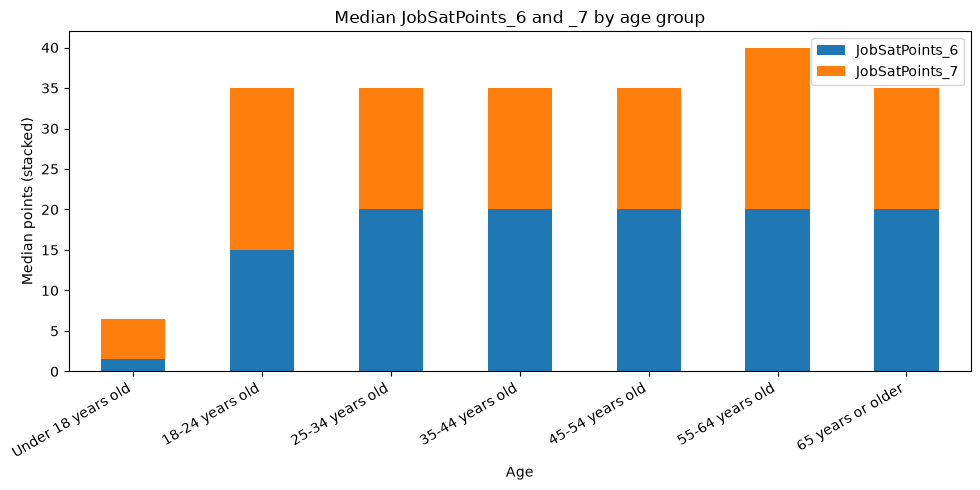

In [9]:
m = df.groupby('Age')[['JobSatPoints_6', 'JobSatPoints_7']].median().reindex(age_order)
print(m)
m.plot(kind='bar', stacked=True, figsize=(10, 5))
plt.ylabel('Median points (stacked)')
plt.title('Median JobSatPoints_6 and _7 by age group')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### Task 2: Stacked Chart for Compensation and Job Satisfaction by Age Group


##### This stacked chart visualizes the composition of compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`) specifically for respondents aged 30-35.


                                                    JobSatPoints_6  \
Employment                                                           
Employed, full-time                                           20.0   
Employed, full-time;Independent contractor, fre...            15.0   
Independent contractor, freelancer, or self-emp...            20.0   
Not employed, but looking for work                            20.0   
Student, full-time                                             NaN   

                                                    JobSatPoints_7  
Employment                                                          
Employed, full-time                                           15.0  
Employed, full-time;Independent contractor, fre...            15.0  
Independent contractor, freelancer, or self-emp...            10.0  
Not employed, but looking for work                            20.0  
Student, full-time                                             NaN  


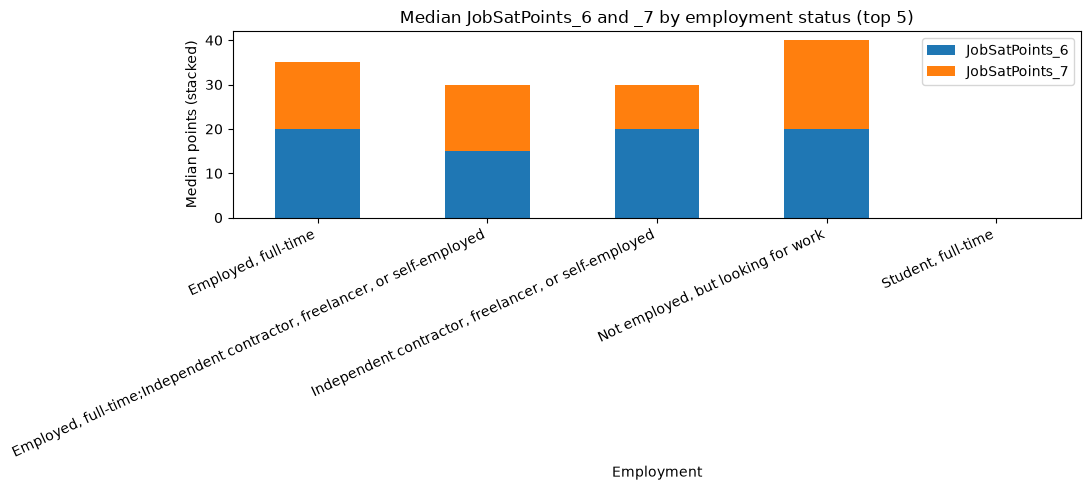

In [10]:
m = df[df['Employment'].isin(top_emp)].groupby('Employment')[['JobSatPoints_6', 'JobSatPoints_7']].median()
print(m)
m.plot(kind='bar', stacked=True, figsize=(11, 5))
plt.ylabel('Median points (stacked)')
plt.title('Median JobSatPoints_6 and _7 by employment status (top 5)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

##### Stacked Chart of Median Compensation and Job Satisfaction Across Age Group


Compare the median compensation and job satisfaction metrics across different age groups. This helps visualize how compensation and satisfaction levels differ by age.


                 ConvertedCompYearly  JobSatPoints_6
Age                                                 
25-34 years old              59825.0            20.0
35-44 years old              84796.0            20.0


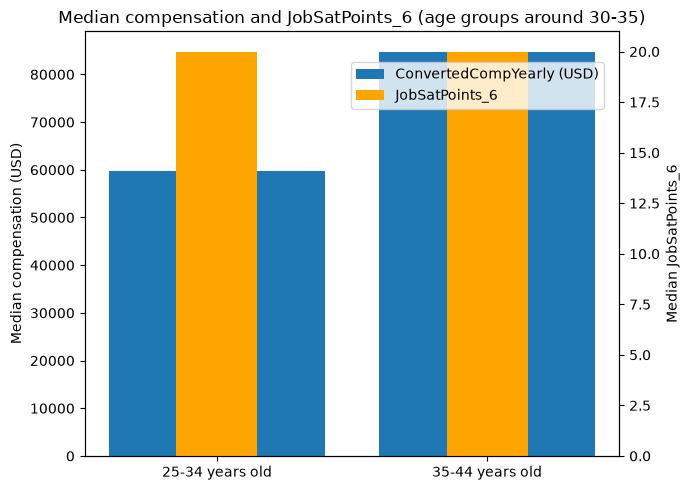

In [11]:
sub = df[df['Age'].isin(['25-34 years old', '35-44 years old'])]
m = sub.groupby('Age')[['ConvertedCompYearly', 'JobSatPoints_6']].median()
print(m)

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.bar(m.index, m['ConvertedCompYearly'], label='ConvertedCompYearly (USD)')
ax1.set_ylabel('Median compensation (USD)')
ax2 = ax1.twinx()
ax2.bar(m.index, m['JobSatPoints_6'], bottom=0, width=0.3, color='orange', label='JobSatPoints_6')
ax2.set_ylabel('Median JobSatPoints_6')
plt.title('Median compensation and JobSatPoints_6 (age groups around 30-35)')
fig.legend(loc='upper right', bbox_to_anchor=(0.88, 0.88))
plt.tight_layout()
plt.show()

### Task 3: Comparing Data Using Stacked Charts


##### 1. Stacked Chart of Preferred Databases by Age Group




Visualize the top databases that respondents from different age groups wish to learn. Create a stacked chart to show the proportion of each database in each age group.


                    ConvertedCompYearly  JobSatPoints_6
Age                                                    
Under 18 years old               7626.5             1.5
18-24 years old                 25000.0            15.0
25-34 years old                 59825.0            20.0
35-44 years old                 84796.0            20.0
45-54 years old                 99099.0            20.0
55-64 years old                109691.0            20.0
65 years or older              106000.0            20.0


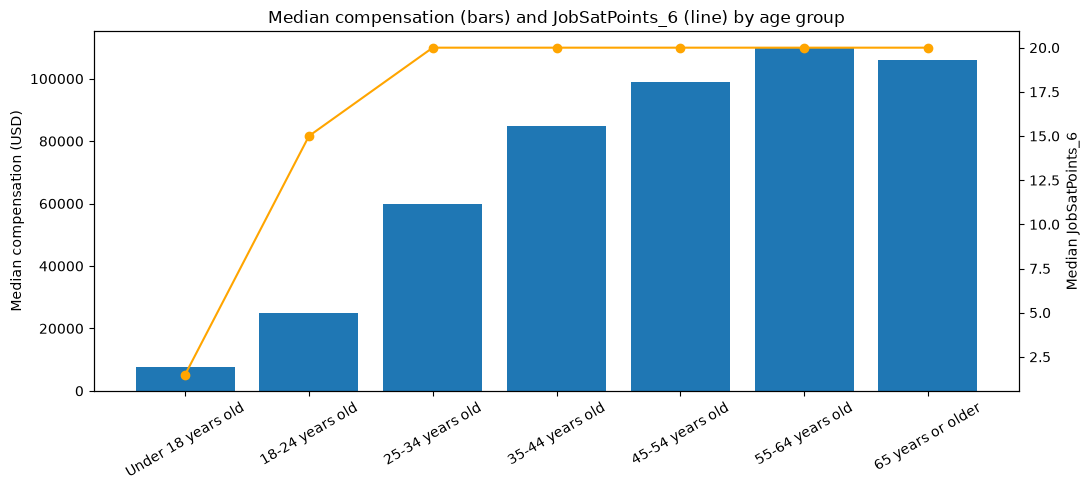

In [12]:
m = df.groupby('Age')[['ConvertedCompYearly', 'JobSatPoints_6']].median().reindex(age_order)
print(m)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(m.index, m['ConvertedCompYearly'])
ax1.set_ylabel('Median compensation (USD)')
ax2 = ax1.twinx()
ax2.plot(m.index, m['JobSatPoints_6'], color='orange', marker='o')
ax2.set_ylabel('Median JobSatPoints_6')
plt.title('Median compensation (bars) and JobSatPoints_6 (line) by age group')
ax1.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

##### 2. Stacked Chart of Employment Type by Job Satisfaction


Analyze the distribution of employment types within each job satisfaction level using a stacked chart. This will provide insights into how employment types are distributed across various satisfaction ratings.


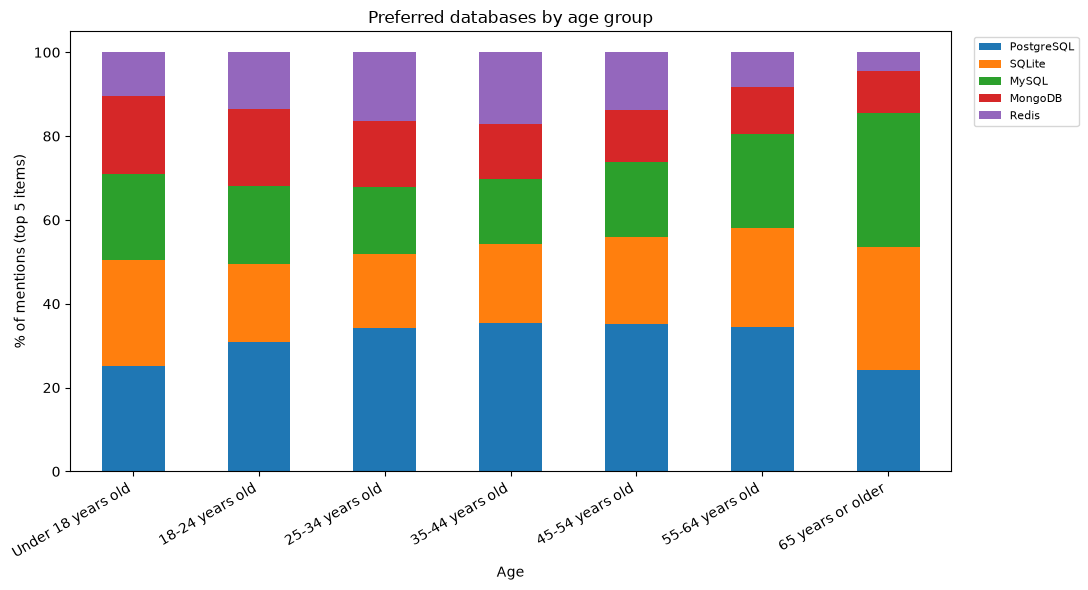

In [13]:
stacked_share('Age', 'DatabaseWantToWorkWith', 'Preferred databases by age group', order=age_order)

### Task 4: Exploring Technology Preferences Using Stacked Charts


##### 1. Stacked Chart for Preferred Programming Languages by Age Group


Analyze how programming language preferences (`LanguageAdmired`) vary across age groups.


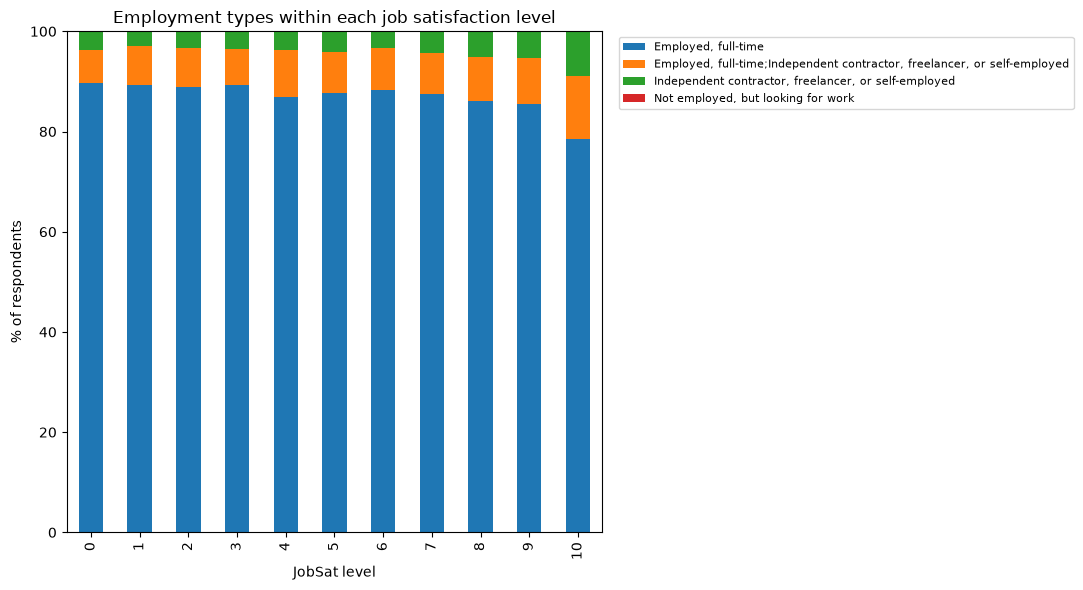

In [14]:
d = df[df['Employment'].isin(top_emp)].dropna(subset=['JobSat']).copy()
d['JobSat'] = d['JobSat'].round().astype(int)
ct = pd.crosstab(d['JobSat'], d['Employment'])
(ct.div(ct.sum(axis=1), axis=0) * 100).plot(kind='bar', stacked=True, figsize=(11, 6))
plt.ylabel('% of respondents')
plt.xlabel('JobSat level')
plt.title('Employment types within each job satisfaction level')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

##### 2. Stacked Chart for Technology Adoption by Employment Type


Explore how admired platforms (`PlatformAdmired`) differ across employment types (e.g., full-time, freelance)


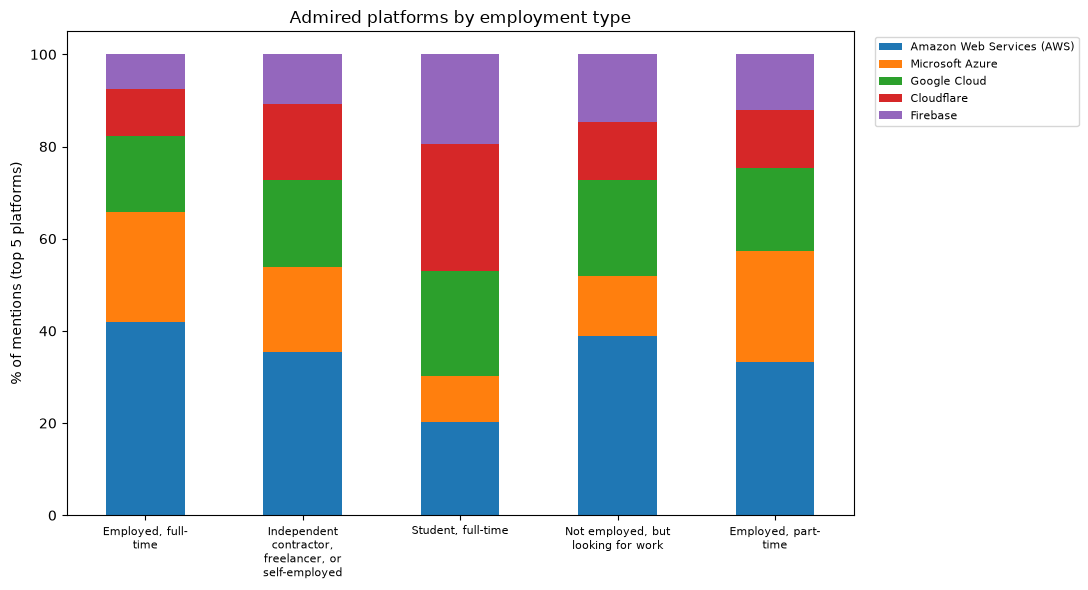

In [16]:
import textwrap

single = df[~df['Employment'].fillna('').str.contains(';')]
top_single = single['Employment'].value_counts().head(5).index.tolist()

d = single[single['Employment'].isin(top_single)][['Employment', 'PlatformAdmired']].dropna()
d = d.assign(item=d['PlatformAdmired'].str.split(';')).explode('item')
d['item'] = d['item'].str.strip()
top = d['item'].value_counts().head(5).index
ct = pd.crosstab(d['Employment'], d['item'])[top]
ct = ct.reindex(top_single)
ct.index = [textwrap.fill(i, 18) for i in ct.index]    # wrap long labels onto several lines

(ct.div(ct.sum(axis=1), axis=0) * 100).plot(kind='bar', stacked=True, figsize=(11, 6))
plt.ylabel('% of mentions (top 5 platforms)')
plt.title('Admired platforms by employment type')
plt.xticks(rotation=0, fontsize=8)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

In [17]:
share = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
share.index = [i.replace('\n', ' ') for i in share.index]
print(share)

lead = share.idxmax(axis=1)                       # most admired platform per employment type
lead_val = share.max(axis=1)
overall = share.mean().sort_values(ascending=False)

print("\nLeading platform per group:")
for grp in share.index:
    print(f"- {grp}: {lead[grp]} ({lead_val[grp]}%)")

second = overall.index[1]
low_grp, high_grp = share[second].idxmin(), share[second].idxmax()
print(f"\nNote: The most admired platform overall is {overall.index[0]}. "
      f"{second} varies most, from {share[second].min()}% ({low_grp}) "
      f"to {share[second].max()}% ({high_grp}). "
      f"Percentages show shares among the top 5 platforms only.")

item                                                Amazon Web Services (AWS)  \
Employed, full- time                                                     42.0   
Independent contractor, freelancer, or self-emp...                       35.5   
Student, full-time                                                       20.3   
Not employed, but looking for work                                       39.0   
Employed, part- time                                                     33.3   

item                                                Microsoft Azure  \
Employed, full- time                                           23.7   
Independent contractor, freelancer, or self-emp...             18.4   
Student, full-time                                             10.0   
Not employed, but looking for work                             12.8   
Employed, part- time                                           24.0   

item                                                Google Cloud  Cloudflare  \
Employ

### Final Step: Review


In this lab, you focused on using stacked charts to understand the composition and comparison within the dataset. Stacked charts provided insights into job satisfaction, compensation, and preferred databases across age groups and employment types.


## Summary


After completing this lab, you will be able to:

- Use stacked charts to analyze the composition of data across categories, such as job satisfaction and compensation by age group.

- Compare data across different dimensions using stacked charts, enhancing your ability to communicate complex relationships in the data.

- Visualize distributions across multiple categories, such as employment type by satisfaction, to gain a deeper understanding of patterns within the dataset.


## Author:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
